# Segunda ronda: más ideas de ML para FWI

Mismo protocolo que en `ml_ideas_fwi.ipynb`: el problema de juguete de `fwi_toy.py` (acústica 2D en lugar de
SPECFEM3D), un **presupuesto de 100 simulaciones** que lo cuenta todo (forward, adjuntas, Born) y controles no
aprendidos. Las ideas se prueban en el orden propuesto:

| Fase | Idea | Pregunta | Configuración |
|---|---|---|---|
| A | Precondicionador aprendido (P) ajustado también con productos **H·v exactos** + control **pseudo-Hessiano** | ¿Mejoran a P? ¿Le gana un precondicionador clásico? | pozos + superficie, modelo inicial suavizado |
| B | **Regularización con un denoiser CNN** entrenado offline con modelos geológicos aleatorios | ¿Mejora el modelo con mala iluminación? Controles: Tikhonov y TV | **solo superficie** |
| C | **Extrapolación de bajas frecuencias** con una CNN 1D, y misfit **W1** (transporte óptimo) | ¿Evita el cycle skipping? | datos solo > 4 Hz, **modelo inicial 1D un 12 % lento** |

Los resultados se cachean en `results/<config>/`, donde `<config>` es `s1`, `s2`, `s1-surf`, `s2-surf`, `s1-poor` o
`s2-poor`. Para regenerarlos:
`PYTHONPATH=. FWI_SCENARIO=1 FWI_ACQ=surface python run_ml_experiments.py L-BFGS DEN_100 ...`
Los modelos ML (denoiser, red de bajas frecuencias) se guardan en `results/models_ml/`.

In [1]:
import os, subprocess, sys
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: f"{x:.3g}")
CFG = {"s1": {}, "s2": {}, "s1-surf": {"FWI_ACQ": "surface"}, "s2-surf": {"FWI_ACQ": "surface"},
       "s1-poor": {"FWI_INIT": "poor"}, "s2-poor": {"FWI_INIT": "poor"}}
env0 = dict(os.environ, PYTHONPATH=".")
R, MOD = {}, {}
for tag, extra in CFG.items():
    sc = tag[1]
    env = dict(env0, FWI_SCENARIO=sc, **extra)
    if not os.path.exists(f"results/{tag}/models.npz"):
        code = ("import numpy as np, fwi_toy as T; np.savez('results/%s/models.npz', v_true=T.v_true_np, "
                "v_init=T.v_init_np, mask=T.mask_np)" % tag)
        subprocess.run([sys.executable, "-c", code], env=env, check=True)
    MOD[tag] = np.load(f"results/{tag}/models.npz")
    R[tag] = {f[:-3]: torch.load(f"results/{tag}/{f}", weights_only=False, map_location="cpu")
              for f in sorted(os.listdir(f"results/{tag}")) if f.endswith(".pt")}
print({t: len(r) for t, r in R.items()})


def row(tag, n):
    d = R[tag][n]
    err0 = d.get("err0", d["log"][0]["err"])
    return {"err modelo": d["err"], "err/err0": d["err"] / err0, "J datos final": d.get("Jd", d["J"]),
            "born": d["n_born"], "sims": d["n_sims"]}


def table(tag, names):
    return pd.DataFrame({n: row(tag, n) for n in names if n in R[tag]}).T

{'s1': 22, 's2': 19, 's1-surf': 15, 's2-surf': 15, 's1-poor': 8, 's2-poor': 8}


## Fase A: precondicionadores (configuración de pozos, como en la ronda 1)

- `L-BFGS+PH<ε>`: H0 = γ·diag(1/(h + ε max h)), donde h es el pseudo-Hessiano de Shin (Σ_s Σ_t (∂²_t u_s)²). En
  SPECFEM se acumula durante el forward, así que no cuesta simulaciones.
- `L-BFGS+P+Hv<k>`: cada k iteraciones se pide un producto Gauss-Newton H·g exacto (1 Born + 1 adjunta = 2 sims),
  y P se ajusta también a P(Hv) ≈ v.
- `L-BFGS+P-b<b>`: P con la iluminación acotada a a² ∈ [1/b, b] (motivado por la fase B).

s1                       s2                
                  J/J0 err modelo born     J/J0 err modelo born
L-BFGS        0.000759     0.0069    0 0.000174    0.00335    0
L-BFGS-mem50  0.000421    0.00625    0 6.77e-05    0.00298    0
L-BFGS+PH0.02 0.000742    0.00689    0 0.000136    0.00321    0
L-BFGS+PH0.1    0.0008    0.00696    0 0.000139    0.00323    0
L-BFGS+P      2.01e-05    0.00499    0 4.99e-05      0.003    0
L-BFGS+P+Hv10 0.000177    0.00554    5 0.000107    0.00322    5
L-BFGS+P+Hv5  0.000144    0.00546    8 0.000127    0.00335    8
L-BFGS+P-b3   1.24e-05    0.00502    0 2.79e-05    0.00288    0
L-BFGS+P-b10  1.77e-05    0.00502    0 3.48e-05    0.00301    0

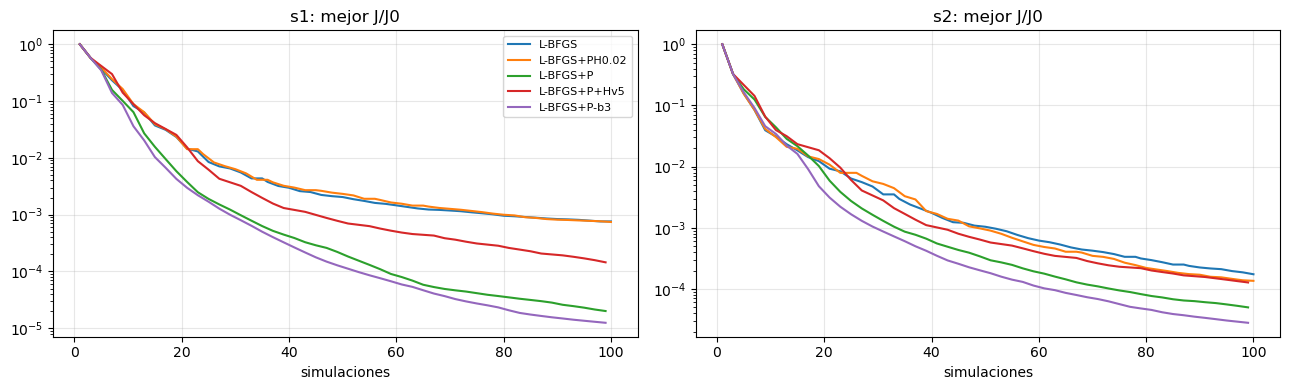

In [2]:
A_NAMES = ["L-BFGS", "L-BFGS-mem50", "L-BFGS+PH0.02", "L-BFGS+PH0.1", "L-BFGS+P", "L-BFGS+P+Hv10", "L-BFGS+P+Hv5",
           "L-BFGS+P-b3", "L-BFGS+P-b10"]
tA = pd.concat({t: table(t, A_NAMES)[["err modelo", "J datos final", "born"]] for t in ["s1", "s2"]}, axis=1)
for t in ["s1", "s2"]:
    J0 = R[t]["L-BFGS"]["trace"][0][1]
    tA[(t, "J/J0")] = tA[(t, "J datos final")] / J0
display(tA[[(t, c) for t in ["s1", "s2"] for c in ["J/J0", "err modelo", "born"]]])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for j, t in enumerate(["s1", "s2"]):
    J0 = R[t]["L-BFGS"]["trace"][0][1]
    for n in ["L-BFGS", "L-BFGS+PH0.02", "L-BFGS+P", "L-BFGS+P+Hv5", "L-BFGS+P-b3"]:
        if n in R[t]:
            tr = np.array(R[t][n]["trace"])
            ax[j].semilogy(tr[:, 0], np.minimum.accumulate(tr[:, 1]) / J0, label=n)
    ax[j].set(title=f"{t}: mejor J/J0", xlabel="simulaciones"); ax[j].grid(alpha=.3)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## Fase B: adquisición solo en superficie y regularización aprendida

El denoiser D es una CNN residual de 8 capas. Se entrena offline con 6000 modelos geológicos aleatorios
(gradiente, capas buzantes con fallas, lentes, anomalías y capas delgadas), quitando ruido correlacionado y
desenfoque, y nunca ve los modelos de prueba. En la inversión se usa la penalización R(m) = ½λ‖m − D(m)‖²_mask,
que tiene gradiente exacto por autograd y **no cuesta simulaciones**.

Controles: Tikhonov (½λ‖∇m‖²) y TV (λ Σ|∇m|). Para cada método se barre λ en 3 valores. Elegir el mejor λ usa
el modelo verdadero (selección oráculo); se hace igual para todos los métodos.

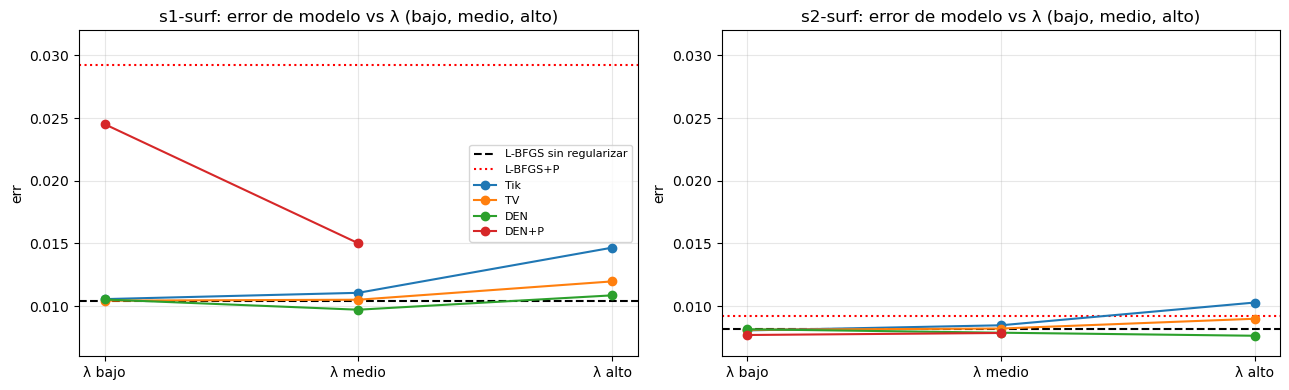

s1-surf                           s2-surf           \
             err modelo err/err0 J datos final err modelo err/err0   
L-BFGS           0.0104    0.343       0.00129    0.00819     0.35   
Tik_1            0.0106    0.347       0.00132    0.00806    0.345   
TV_0.01          0.0104    0.343       0.00129    0.00811    0.347   
DEN_100         0.00972    0.319       0.00115    0.00788    0.337   
DEN_1000         0.0109    0.356       0.00176    0.00764    0.327   
L-BFGS+P         0.0292    0.959      0.000304    0.00918    0.393   
L-BFGS+P-b3      0.0121    0.396      0.000467    0.00852    0.365   
L-BFGS+P-b10     0.0188    0.617      0.000207    0.00954    0.408   
DEN+P_100        0.0245    0.805      0.000373     0.0077    0.329   
DEN+P_1000        0.015    0.493       0.00105    0.00786    0.336   

                            
             J datos final  
L-BFGS            0.000971  
Tik_1             0.000929  
TV_0.01           0.000974  
DEN_100            0.00103  
DEN_1000           0.00156  
L-BFGS+P          0.000482  
L-BFGS+P-b3        0.00031  
L-BFGS+P-b10      0.000367  
DEN+P_100         0.000437  
DEN+P_1000         0.00138

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for j, t in enumerate(["s1-surf", "s2-surf"]):
    base = R[t]["L-BFGS"]["err"]
    ax[j].axhline(base, c="k", ls="--", label="L-BFGS sin regularizar")
    ax[j].axhline(R[t]["L-BFGS+P"]["err"], c="r", ls=":", label="L-BFGS+P")
    for kind, lams in [("Tik", ["1", "10", "100"]), ("TV", ["0.01", "0.1", "1"]), ("DEN", ["10", "100", "1000"]),
                       ("DEN+P", ["100", "1000"])]:
        xs = [i for i, l in enumerate(lams) if f"{kind}_{l}" in R[t]]
        ax[j].plot(xs, [R[t][f"{kind}_{lams[i]}"]["err"] for i in xs], "o-", label=kind)
    ax[j].set(title=f"{t}: error de modelo vs λ (bajo, medio, alto)", xticks=[0, 1, 2],
              xticklabels=["λ bajo", "λ medio", "λ alto"], ylabel="err"); ax[j].grid(alpha=.3)
    ax[j].set_ylim(0.006, 0.032)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

B_NAMES = ["L-BFGS", "Tik_1", "TV_0.01", "DEN_100", "DEN_1000", "L-BFGS+P", "L-BFGS+P-b3", "L-BFGS+P-b10",
           "DEN+P_100", "DEN+P_1000"]
display(pd.concat({t: table(t, B_NAMES)[["err modelo", "err/err0", "J datos final"]] for t in ["s1-surf", "s2-surf"]},
                  axis=1))

### ¿Por qué falla P en superficie? Error por profundidad e iluminación aprendida

0–0.4 km  0.4–0.8 km  0.8–1.2 km
s1-surf L-BFGS       0.000905      0.0056      0.0157
        DEN_100      0.000786     0.00482      0.0147
        L-BFGS+P      0.00198      0.0161      0.0438
        L-BFGS+P-b3   0.00154     0.00989      0.0165
        DEN+P_1000    0.00164      0.0112      0.0212
s2-surf L-BFGS        0.00314      0.0055      0.0116
        DEN_100       0.00305     0.00471      0.0114
        L-BFGS+P      0.00292     0.00848      0.0118
        L-BFGS+P-b3   0.00259     0.00595      0.0121
        DEN+P_1000    0.00311     0.00612      0.0107

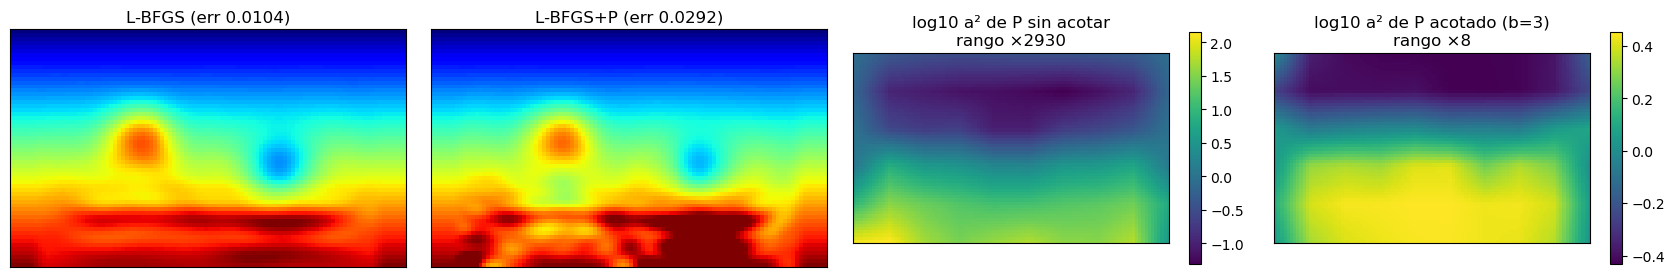

In [4]:
def depth_err(tag, n):
    m = R[tag][n]["m"].numpy(); vt, mk = MOD[tag]["v_true"], MOD[tag]["mask"]
    e = ((m - vt) / vt) ** 2 * mk
    return [np.sqrt(e[a:b].sum() / mk[a:b].sum()) for a, b in [(0, 20), (20, 40), (40, 60)]]

rows = {(t, n): depth_err(t, n) for t in ["s1-surf", "s2-surf"]
        for n in ["L-BFGS", "DEN_100", "L-BFGS+P", "L-BFGS+P-b3", "DEN+P_1000"] if n in R[t]}
display(pd.DataFrame(rows, index=["0–0.4 km", "0.4–0.8 km", "0.8–1.2 km"]).T)

shows = [("L-BFGS+P", "a² de P sin acotar"), ("L-BFGS+P-b3", "a² de P acotado (b=3)")]
fig, ax = plt.subplots(1, 2 + len(shows), figsize=(17, 3.2))
t = "s1-surf"; vt = MOD[t]["v_true"]; kw = dict(vmin=vt.min(), vmax=vt.max(), cmap="jet")
ax[0].imshow(R[t]["L-BFGS"]["m"].numpy(), **kw); ax[0].set_title(f"L-BFGS (err {R[t]['L-BFGS']['err']:.4f})")
ax[1].imshow(R[t]["L-BFGS+P"]["m"].numpy(), **kw); ax[1].set_title(f"L-BFGS+P (err {R[t]['L-BFGS+P']['err']:.4f})")
for k, (n, ttl) in enumerate(shows):
    if n in R[t]:
        il = R[t][n]["precond"]["illum"]
        im = ax[2 + k].imshow(np.log10(il), cmap="viridis"); plt.colorbar(im, ax=ax[2 + k], shrink=.8)
        ax[2 + k].set_title(f"log10 {ttl}\nrango ×{il.max() / il.min():.0f}")
for a in ax:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## Fase C: cycle skipping

**Montaje:**
- Los "datos registrados" son solo la banda > 4 Hz (Butterworth de fase cero), con una ondícula Ricker de 5 Hz.
- El modelo inicial es un gradiente 1D **un 12 % más lento**, sin estructura lateral (err0 ≈ 0.12).

**Métodos (todos con 100 simulaciones):**
- `HP-L2`: L2 directo en banda alta. Es la línea base y debería sufrir cycle skipping.
- `HP-W1`: misfit de transporte óptimo W1 por traza (normalización lineal) en banda alta. `W1-L2`: 40 sims con W1
  y luego L2.
- `MS-oracle`: multiescala con las bajas frecuencias **reales** (< 2 Hz): 40 sims en banda baja y 60 en alta. Es
  la cota superior.
- `MS-ML`: igual que el oráculo, pero la banda baja la **predice una CNN 1D** a partir de la banda alta de cada
  traza (y su offset). La red se entrena offline con los datos simulados de 300 modelos aleatorios
  (≈ 400 000 trazas). Ese entrenamiento cuesta 300 simulaciones *offline*, reutilizables para cualquier
  inversión en la misma geometría.
- `+P`: además, el precondicionador aprendido en cada etapa.

In [5]:
C_NAMES = ["HP-L2", "HP-W1", "W1-L2", "MS-ML", "MS-ML+P", "MS-ML+P-b3", "MS-oracle", "MS-oracle+P"]
tC = pd.concat({t: table(t, C_NAMES)[["err modelo", "err/err0"]] for t in ["s1-poor", "s2-poor"]}, axis=1)
display(tC)
for t in ["s1-poor", "s2-poor"]:
    print(f"{t}: error relativo de la banda baja predicha por la CNN = {R[t]['MS-ML']['lowfreq']['rel_err']:.3f}")

s1-poor             s2-poor         
            err modelo err/err0 err modelo err/err0
HP-L2             0.15     1.24      0.147     1.25
HP-W1             0.18     1.48     0.0322    0.274
W1-L2            0.158      1.3     0.0275    0.234
MS-ML           0.0182     0.15     0.0175    0.149
MS-ML+P        0.00786   0.0648     0.0223     0.19
MS-ML+P-b3     0.00671   0.0553     0.0166    0.141
MS-oracle      0.00903   0.0744     0.0132    0.112
MS-oracle+P    0.00577   0.0475     0.0162    0.138

s1-poor: error relativo de la banda baja predicha por la CNN = 0.122
s2-poor: error relativo de la banda baja predicha por la CNN = 0.121


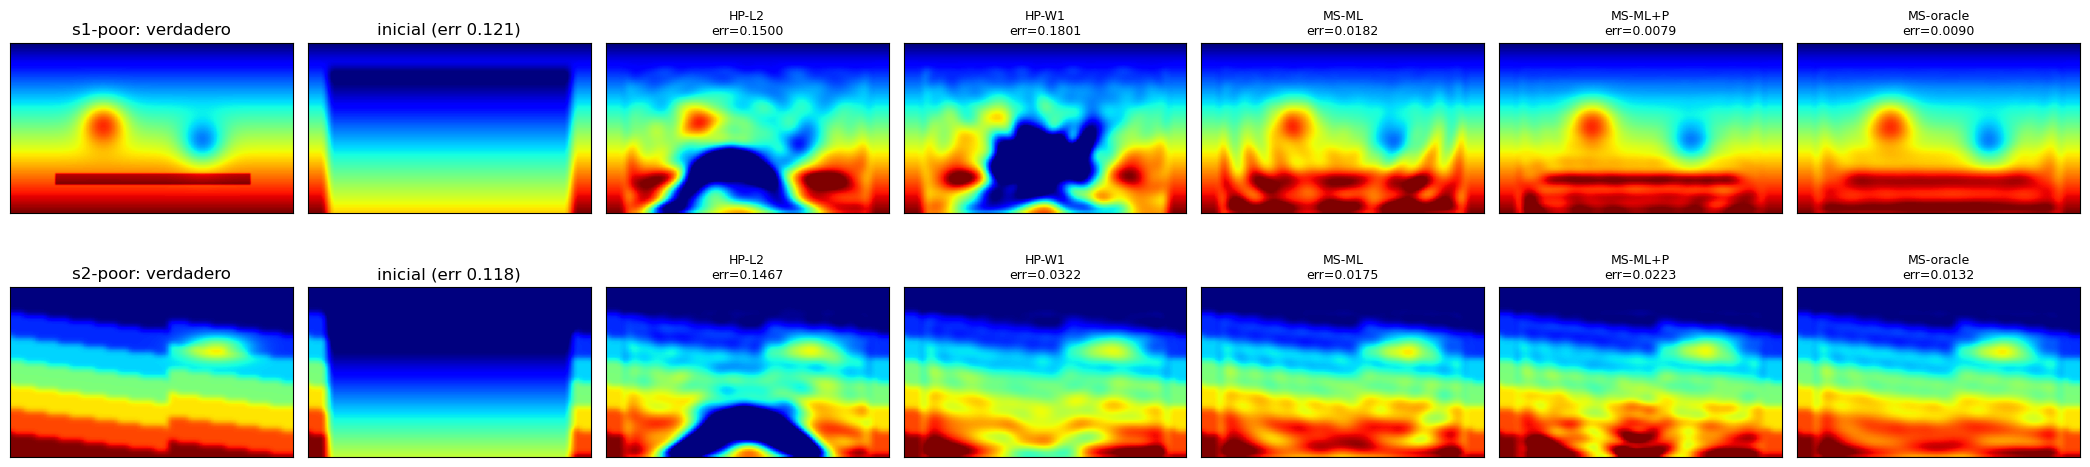

In [6]:
fig, ax = plt.subplots(2, 7, figsize=(21, 5.4))
SHOWC = ["HP-L2", "HP-W1", "MS-ML", "MS-ML+P", "MS-oracle"]
for i, t in enumerate(["s1-poor", "s2-poor"]):
    vt, vi = MOD[t]["v_true"], MOD[t]["v_init"]; kw = dict(vmin=vt.min(), vmax=vt.max(), cmap="jet")
    ax[i, 0].imshow(vt, **kw); ax[i, 0].set_title(f"{t}: verdadero")
    ax[i, 1].imshow(vi, **kw); ax[i, 1].set_title(f"inicial (err {R[t]['HP-L2']['log'][0]['err']:.3f})")
    for k, n in enumerate(SHOWC):
        if n in R[t]:
            ax[i, 2 + k].imshow(R[t][n]["m"].numpy(), **kw)
            ax[i, 2 + k].set_title(f"{n}\nerr={R[t][n]['err']:.4f}", fontsize=9)
for a in ax.flat:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

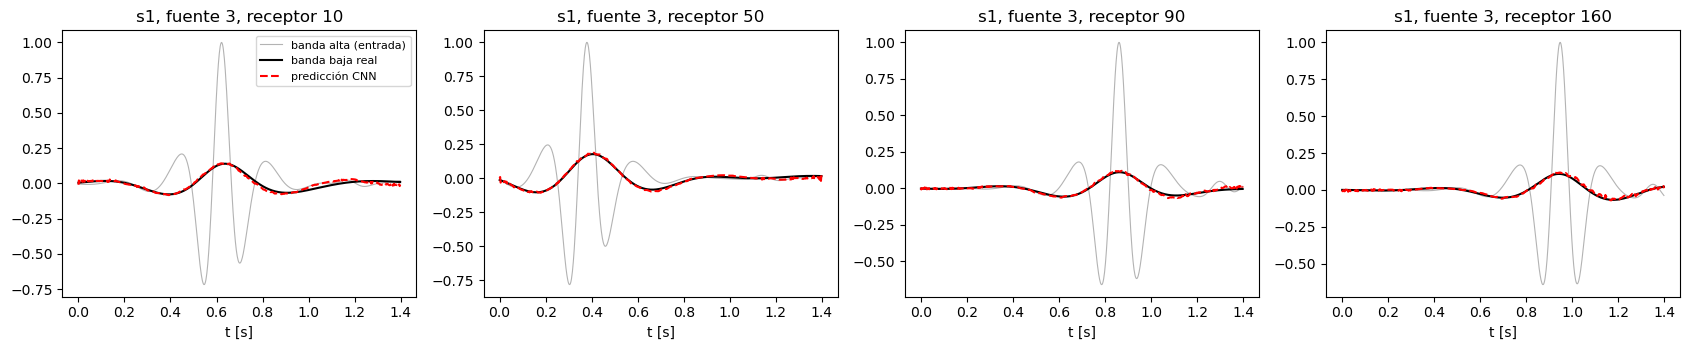

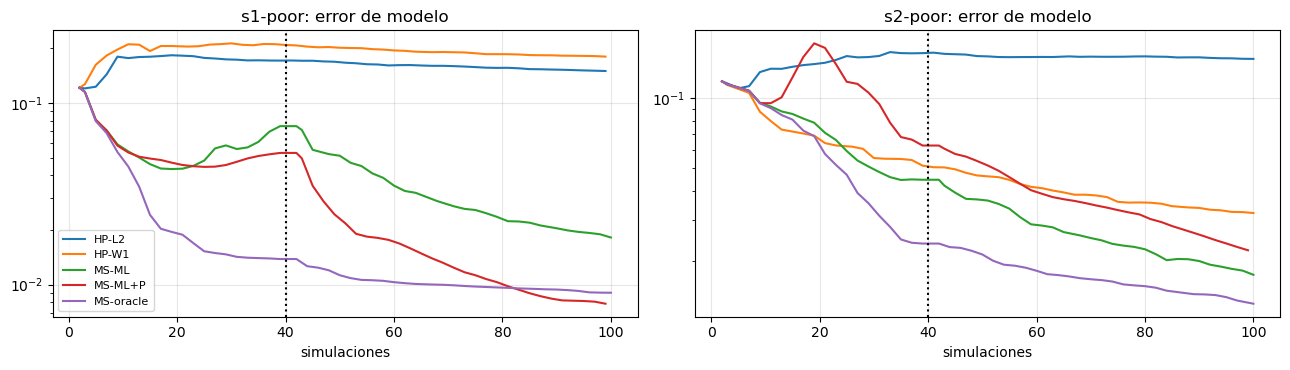

In [7]:
lf = R["s1-poor"]["MS-ML"]["lowfreq"]
t_ax = np.arange(lf["true"].shape[0]) * 0.002
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
for k, rec in enumerate([10, 50, 90, 160]):
    hp = lf["hp"][:, rec].numpy(); s = np.abs(hp).max()
    ax[k].plot(t_ax, hp / s, c="0.7", lw=.8, label="banda alta (entrada)")
    ax[k].plot(t_ax, lf["true"][:, rec].numpy() / s, "k", label="banda baja real")
    ax[k].plot(t_ax, lf["pred"][:, rec].numpy() / s, "r--", label="predicción CNN")
    ax[k].set(title=f"s1, fuente 3, receptor {rec}", xlabel="t [s]")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for j, t in enumerate(["s1-poor", "s2-poor"]):
    for n in ["HP-L2", "HP-W1", "MS-ML", "MS-ML+P", "MS-oracle"]:
        if n in R[t]:
            lg = [(e["sims"], e["err"]) for e in R[t][n]["log"]]
            ax[j].plot(*np.array(lg).T, label=n)
    ax[j].axvline(40, c="k", ls=":"); ax[j].set(title=f"{t}: error de modelo", xlabel="simulaciones", yscale="log")
    ax[j].grid(alpha=.3)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## Conclusiones

Todo se mide con 100 simulaciones. "err" es el error relativo RMS del modelo en la zona invertida.

**Fase A: precondicionador.**

- **El pseudo-Hessiano clásico no explica la ganancia de P.** En s1 queda igual que L-BFGS (err 0.0069) y en s2
  mejora poco (0.0032 frente a 0.0034). P aprendido sigue claramente por delante: s1 0.0050 y s2 0.0030.
- **Añadir productos H·v exactos empeora a P.** Con H·v cada 5 o 10 iteraciones, s1 sube a err 0.0055 y J/J0 a
  ≈1.5e-4 (frente a 2e-5 sin H·v). Cada producto cuesta 2 simulaciones y la información extra no las paga; además
  el H de Gauss-Newton no coincide con el que miden los pares secantes.
- **Acotar la iluminación (a² ∈ [1/3, 3]) conserva o mejora la ganancia.** s1: err 0.0050, J/J0 1.2e-5. s2:
  err 0.0029, el mejor resultado. Es la versión recomendada (ver fase B).

**Fase B: adquisición solo en superficie.**

- **Hallazgo negativo importante: P sin acotar es peligroso con mala iluminación.** Ajusta los datos 4× mejor
  que L-BFGS, pero el error de modelo casi no baja (s1: 0.0292 frente a 0.0104). Aprende una "iluminación" con un
  rango de ×2900 que amplifica las direcciones del fondo que los datos casi no ven: el error en 0.8–1.2 km pasa de
  0.016 a 0.044. Acotarla reduce el daño (0.0121), pero en superficie P sigue sin superar a L-BFGS.
- **El denoiser CNN como regularizador da una mejora pequeña y consistente.** El error baja un 7 % en ambos
  escenarios (s1: 0.0097 frente a 0.0104; s2: 0.0076 frente a 0.0082), sin costo en simulaciones. Tikhonov y TV
  no mejoran nada con ningún λ. La salvedad es que el λ óptimo cambia entre escenarios (100 frente a 1000) y aquí
  se eligió con el modelo verdadero.
- **Denoiser + P:** en s2 queda bien (0.0077), pero en s1 no evita el problema de P (0.0150).

**Fase C: cycle skipping (la mayor ganancia de toda la serie).**

- **El escenario es realmente difícil.** Con datos solo > 4 Hz y el modelo inicial 1D un 12 % lento, L2 directo
  *diverge*: err 0.121 → 0.150 en s1 y 0.118 → 0.147 en s2.
- **La extrapolación de bajas frecuencias con una CNN rescata la inversión.** s1: err 0.018; s2: err 0.018.
  El oráculo con las bajas reales llega a 0.009 y 0.013. La banda baja predicha tiene ≈12 % de error relativo,
  suficiente para quedar dentro de la cuenca de atracción.
- **Combinada con P acotado** es la mejor configuración de s1 (err 0.0067), cerca del oráculo + P (0.0058). En s2,
  P empeora tanto la versión ML como el oráculo (0.017 y 0.016 frente a 0.0175 y 0.013 sin P). El beneficio de P
  depende del caso.
- **El misfit W1 (transporte óptimo) es inconsistente.** En s2 evita la divergencia (err 0.028–0.032), aunque
  queda peor que la ruta ML. En s1 también diverge (0.16–0.18).

**Salvedades:**
- El denoiser y la red de bajas frecuencias se entrenaron con modelos de la misma familia geológica que los de
  prueba. Es el caso favorable: con datos reales, la diferencia entre el prior y la geología real reducirá la
  ganancia.
- La red de bajas frecuencias cuesta ≈300 simulaciones offline. Se amortizan si se reutiliza para muchas
  inversiones con la misma geometría y la misma ondícula.
- El problema es 2D y de juguete, con datos sin ruido.

**Recomendación para SPECFEM3D, por orden:**
1. Extrapolación de bajas frecuencias con ML, si el modelo inicial es malo o faltan bajas frecuencias. Es lo
   único que cambió el resultado de forma cualitativa: pasa de divergir a converger.
2. El precondicionador aprendido **con la iluminación acotada**, solo con buena cobertura (pozos o transmisión).
   Con adquisición solo en superficie, mejor L-BFGS estándar.
3. El denoiser como regularizador: es barato y seguro, pero la ganancia es pequeña.
4. Los productos H·v para P y el misfit W1 no se recomiendan.